In [1]:
import os
import mdtraj as md
import numpy as np
import matplotlib.pyplot as plt
import pickle


N_TIMESTEP_IN_REPLICA = 18000
TEMPERATURE = 300

pickle_dir = "./pickle-cache/pca_protein-all"
if not os.path.exists(pickle_dir):
    os.mkdir(pickle_dir)

gleap_target = md.load("../20250801_FUS-RRM/2_md-preparation-2/gleap.target.gro")

xtcs_cmd = []
for trial in range(5):
    xtc = md.load(f"../20250801_FUS-RRM/6_cmd-{trial+1}/cmd.skip10.whole.target.pbc.xtc", top=gleap_target)[2001:]
    print(trial, xtc.n_frames)  
    xtcs_cmd.append(xtc)

xtcs_pacs = []
for trial in range(50):
    xtc = md.load(f"../20250801_FUS-RRM/7_pacs-1/trial{trial+1:03}/prd.target.trjcat-all.pbc.2.2nm.xtc", top=gleap_target)[::100]
    print(trial, xtc.n_frames)
    xtcs_pacs.append(xtc)

pdbs_nmr = md.load("../20250801_FUS-RRM/1_modelling/1_6gbm.pdb")

0 18000
1 18000
2 18000
3 18000
4 18000
0 1020
1 1261
2 1090
3 1215
4 2089
5 1474
6 2093
7 1215
8 4434
9 1751
10 1292
11 853
12 1166
13 2963
14 1823
15 1284
16 1022
17 1398
18 933
19 342
20 1139
21 1119
22 814
23 739
24 937
25 767
26 1602
27 929
28 1659
29 1175
30 1114
31 461
32 855
33 561
34 127
35 775
36 643
37 1329
38 1412
39 1830
40 610
41 971
42 1125
43 720
44 633
45 2054
46 1949
47 1129
48 1422
49 2033


/work18/kijima/programs/anaconda3/envs/jupyter/lib/python3.10/site-packages/mdtraj/formats/pdb/pdbfile.py:206: UserWarning: Unlikely unit cell vectors detected in PDB file likely resulting from a dummy CRYST1 record. Discarding unit cell vectors.
  warnings.warn(


In [2]:
atom_indices_gleap = [atom.index for atom in gleap_target.topology.atoms if 24<=atom.residue.index<=125]
print(len(atom_indices_gleap))

atom_indices_nmr = [atom.index for atom in pdbs_nmr.topology.atoms if 0<=atom.residue.index<=101]
print(len(atom_indices_nmr))

1564
1564


In [3]:
import sklearn.decomposition

atom_vectors_cmd = [xtc.xyz[:, atom_indices_gleap, :].reshape(xtc.n_frames, len(atom_indices_gleap)*3) for xtc in xtcs_cmd]
atom_vectors_nmr = [pdb.xyz[:, atom_indices_nmr,   :].reshape(pdb.n_frames, len(atom_indices_nmr)  *3) for pdb in pdbs_nmr]

if False:
    pca = sklearn.decomposition.PCA(n_components=2, svd_solver="full")
    pca.fit(np.concatenate(atom_vectors_cmd)[::10])
    pickle.dump(pca, open(f"{pickle_dir}/pca.pickle", "wb"))

pca = pickle.load(open(f"{pickle_dir}/pca.pickle", "rb"))
print(pca.explained_variance_ratio_)

trajs = [pca.transform(_av) for _av in atom_vectors_cmd]

[0.16520493 0.1408441 ]


In [4]:
from sklearn.cluster import KMeans
import matplotlib


def cluster_trajs(trajs, n_clusters):
    clustering_model = KMeans(
        n_clusters=n_clusters,
        init="k-means++",
        n_init=10,
        max_iter=int(1e10),
        tol=1e-10,
        verbose=0,
        random_state=1,
        copy_x=True,
        algorithm="lloyd"
    )
    trajs_concat = np.concatenate(trajs)
    clustered_trajs_concat = clustering_model.fit_predict(trajs_concat)
    return clustered_trajs_concat.reshape(len(trajs), N_TIMESTEP_IN_REPLICA), clustering_model.cluster_centers_


def plot_clusters(ax, trajs, clustered_trajs, cluster_centers):
    trajs_concat = np.concatenate(trajs)
    clustered_trajs_concat = np.concatenate(clustered_trajs)

    ax.scatter(trajs_concat[:, 0], trajs_concat[:, 1], s=0.1, c=[matplotlib.cm.tab20(i_cluster%20) for i_cluster in clustered_trajs_concat])
    for cluster_center in cluster_centers:
        ax.scatter(cluster_center[0], cluster_center[1], color="black", s=5)

    ax.grid(True, color="black", alpha=0.3)
    ax.set_aspect("equal", adjustable="box")

In [5]:
from deeptime.markov import TransitionCountEstimator
from deeptime.markov.msm import MaximumLikelihoodMSM
from deeptime.markov.tools import estimation
from deeptime.util.validation import implied_timescales
import deeptime.plots


def construct_msm(clustered_trajs, lagtimes):
    msm_models = {}
    stationary_distributions = {}

    for lagtime in lagtimes:
        count_estimator = TransitionCountEstimator(
            lagtime=lagtime,
            count_mode="sliding",
            n_states=None,
            sparse=False,
        )
        count_estimator.fit(clustered_trajs)
        count_model = count_estimator.fetch_model()

        msm_constructor = MaximumLikelihoodMSM(
            reversible=True,
            stationary_distribution_constraint=None,
            sparse=False,
            allow_disconnected=False,
            maxiter=int(1e10),
            maxerr=1e-10,
            connectivity_threshold=0,
            transition_matrix_tolerance=1e-10,
            lagtime=None,
            use_lcc=False,
        ) 

        try:
            msm_constructor.fit(count_model)
        except:
            continue

        msm_models[lagtime] = msm_constructor.fetch_model()
        largest_connected_set = estimation.largest_connected_set(count_model.count_matrix, directed=True)
        stationary_distributions[lagtime] = np.zeros(np.max(clustered_trajs)+1)
        stationary_distributions[lagtime][largest_connected_set] = msm_models[lagtime].stationary_distribution

    return msm_models, stationary_distributions


def plot_implied_timescales(ax, msm_models):
    deeptime.plots.plot_implied_timescales(
        implied_timescales(list(msm_models.values())),
        n_its=10,
        ax=ax,
        process=None,
        show_mle=True,
        show_sample_mean=True,
        show_sample_confidence=True,
        show_cutoff=True,
        sample_confidence=0.95,
        colors=None,
    )
    ax.set_xlim(0, np.max(list(msm_models.keys())))
    ax.set_yscale("log")

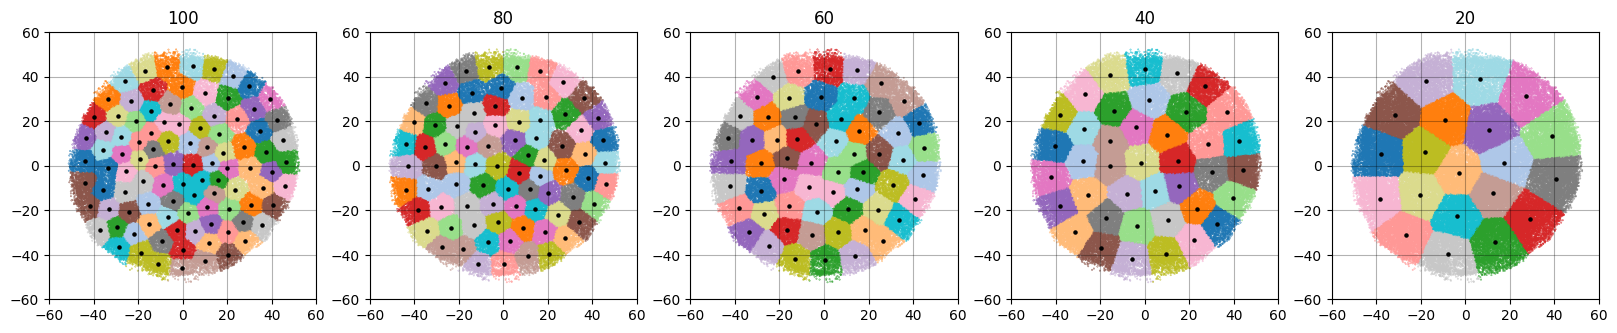

In [6]:
n_clusters_candidates = [100, 80, 60, 40, 20]

fig_cluster, ax_cluster = plt.subplots(1, len(n_clusters_candidates))
fig_cluster.set_size_inches(4*len(n_clusters_candidates), 4)

if False:
    clustered_trajs = {}
    cluster_centers = {}
    for i_clusters, n_clusters in enumerate(n_clusters_candidates):
        print(n_clusters)
        clustered_trajs[n_clusters], cluster_centers[n_clusters] = cluster_trajs(trajs, n_clusters)
    pickle.dump(clustered_trajs, open(f"{pickle_dir}/clustered_trajs.pickle", "wb"))
    pickle.dump(cluster_centers, open(f"{pickle_dir}/cluster_centers.pickle", "wb"))

clustered_trajs = pickle.load(open(f"{pickle_dir}/clustered_trajs.pickle", "rb"))
cluster_centers = pickle.load(open(f"{pickle_dir}/cluster_centers.pickle", "rb"))


for i_clusters, n_clusters in enumerate(n_clusters_candidates):
    plot_clusters(ax_cluster[i_clusters], trajs, clustered_trajs[n_clusters], cluster_centers[n_clusters])
    ax_cluster[i_clusters].set_title(n_clusters)
    ax_cluster[i_clusters].set_xlim(-60, 60)
    ax_cluster[i_clusters].set_ylim(-60, 60)
    ax_cluster[i_clusters].set_xticks(range(-60, 61, 20))
    ax_cluster[i_clusters].set_yticks(range(-60, 61, 20))

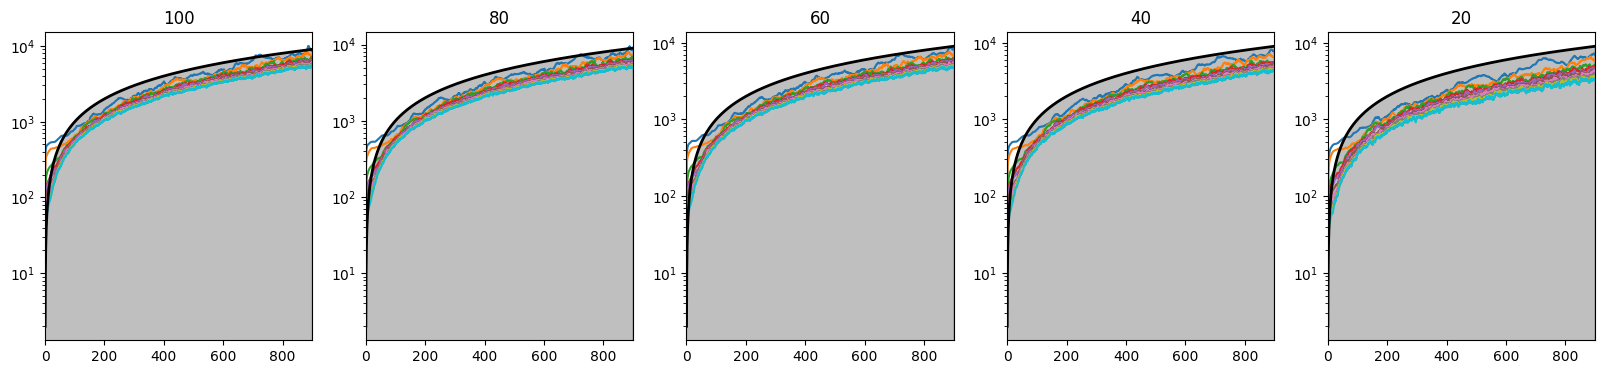

In [7]:
fig_its, ax_its = plt.subplots(1, len(n_clusters_candidates))
fig_its.set_size_inches(4*len(n_clusters_candidates), 4)

if False:
    msm_models = {}
    for i_clusters, n_clusters in enumerate(n_clusters_candidates):
        print(n_clusters)
        msm_models[n_clusters], _ = construct_msm(clustered_trajs[n_clusters], range(2, int(N_TIMESTEP_IN_REPLICA_CMD/2), 2))
    pickle.dump(msm_models , open(f"{pickle_dir}/msm_models.pickle" , "wb"))

msm_models = pickle.load(open(f"{pickle_dir}/msm_models.pickle" , "rb"))


for i_clusters, n_clusters in enumerate(n_clusters_candidates):
    plot_implied_timescales(ax_its[i_clusters], msm_models[n_clusters])
    ax_its[i_clusters].set_title(n_clusters)
    ax_its[i_clusters].set_xticks(range(0, 8001, 2000), range(0, 801, 200))

In [8]:
import scipy.constants
from deeptime.util import energy2d
from scipy.spatial import Voronoi


def plot_energy_landscape(ax, msm_model, trajs, clustered_trajs):
    kbt = scipy.constants.Boltzmann
    kbt *= TEMPERATURE
    kbt *= scipy.constants.Avogadro
    kbt /= scipy.constants.calorie
    kbt /= 1000
    
    weights = msm_model.compute_trajectory_weights(np.concatenate(clustered_trajs))[0]
    energies = energy2d(*np.concatenate(trajs).T, bins=(50, 50), kbt=kbt, weights=weights, shift_energy=True)
    
    ax, contour, cbar = energies.plot(contourf_kws=dict(cmap="nipy_spectral"), ax=ax)
    ax.grid(True, color="black", alpha=0.3)
    ax.set_aspect("equal", adjustable="box")

    return energies, cbar


def compute_metastable_states(msm_model, n_metastable_sets, trajs_concat, clustered_trajs_concat):
    pcca = msm_model.pcca(n_metastable_sets=n_metastable_sets)

    metastabled_trajs_concat = np.zeros(len(clustered_trajs_concat))
    for timestep, cluster_index in enumerate(clustered_trajs_concat):
        metastabled_trajs_concat[timestep] = np.argmax(pcca.memberships[cluster_index])

    boundary_lines = []
    voronoi = Voronoi(trajs_concat)
    for (p1, p2), ridge_vertices in zip(voronoi.ridge_points, voronoi.ridge_vertices):
        if -1 in ridge_vertices:
            continue
        if metastabled_trajs_concat[p1] != metastabled_trajs_concat[p2]:
            v0, v1 = voronoi.vertices[ridge_vertices]
            boundary_lines.append(((v0[0], v1[0]), (v0[1], v1[1])))

    return pcca, metastabled_trajs_concat, boundary_lines


def plot_metastable_states(ax, trajs_concat, metastabled_trajs_concat):
    ax.scatter(*trajs_concat.T, color=[matplotlib.cm.tab10(int(metastable_state_index)%10) for metastable_state_index in metastabled_trajs_concat], s=0.1)

    ax.grid(True, color="black", alpha=0.3)
    ax.set_aspect("equal", adjustable="box")


def plot_voronoi_boundary(ax, boundary_lines):
    for p1, p2 in boundary_lines:
        ax.plot(p1, p2, color="black", linewidth=1)

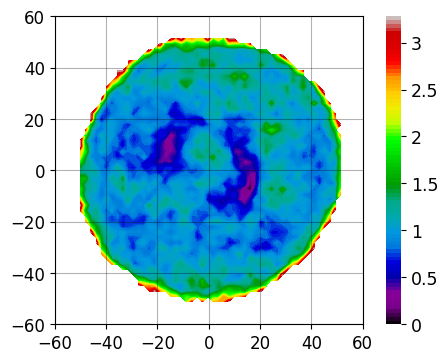

In [9]:
n_clusters = 60
lagtime = 1000

fig, ax = plt.subplots(1, 1)
fig.set_size_inches(6, 4)

energies, cbar = plot_energy_landscape(ax, msm_models[n_clusters][lagtime], trajs, clustered_trajs[n_clusters])
cbar.set_ticks(ticks=[0, 0.5, 1, 1.5, 2, 2.5, 3], labels=[0, 0.5, 1, 1.5, 2, 2.5, 3], size=12.5)

ax.set_xlim(-60, 60)
ax.set_ylim(-60, 60)
ax.set_xticks(range(-60, 61, 20))
ax.set_yticks(range(-60, 61, 20))
ax.tick_params(axis="x", labelsize=12)
ax.tick_params(axis="y", labelsize=12)

In [10]:
tmp = []
for trial in range(5):
    xtc = md.load(f"../20250801_FUS-RRM/6_cmd-{trial+1}/cmd.skip10.whole.target.pbc.xtc", top=gleap_target)[2001:]
    tmp.append(xtc)
xtc_tmp = md.join(tmp)
traj_tmp = pca.transform(xtc_tmp.xyz[:, atom_indices_gleap, :].reshape(xtc_tmp.n_frames, len(atom_indices_gleap)*3))

xtc_tmp[np.argmin(np.abs(np.linalg.norm(traj_tmp-(15, -10), axis=1)))].save_gro("pca_protein-all/0.gro")
xtc_tmp[np.argmin(np.abs(np.linalg.norm(traj_tmp-(-15,  5), axis=1)))].save_gro("pca_protein-all/1.gro")

2
[[0.61512279 0.38487721]
 [0.34778877 0.65221123]]
[0.4746894 0.5253106]
[0.         2.87530847]
[2.59823129 0.        ]

3
[[0.44628833 0.30699044 0.24672124]
 [0.24237918 0.54718781 0.21043301]
 [0.26499198 0.2701788  0.46482923]]
[0.31291102 0.38962805 0.29746093]
[0.         4.01991903 3.89800227]
[3.38552976 0.         3.54492122]

4
[[0.38617133 0.18509553 0.17828372 0.25044942]
 [0.23583759 0.41168238 0.14635766 0.20612237]
 [0.14987003 0.14247683 0.40816875 0.29948439]
 [0.20303518 0.18409555 0.18111203 0.43175723]]
[0.24312581 0.2266247  0.22323526 0.30701423]
[0.         4.80671012 5.3955817  5.03675343]
[5.71888441 0.         6.0358859  5.72696476]

5
[[0.41480713 0.14015402 0.14356893 0.12300493 0.178465  ]
 [0.14832446 0.11944782 0.09295741 0.16803749 0.47123282]
 [0.31127656 0.17676507 0.37853653 0.08999025 0.0434316 ]
 [0.12411806 0.08803236 0.09102894 0.3553154  0.34150524]
 [0.26089296 0.26735821 0.1642329  0.10846089 0.19905504]]
[0.27116492 0.16457732 0.17224206 0.

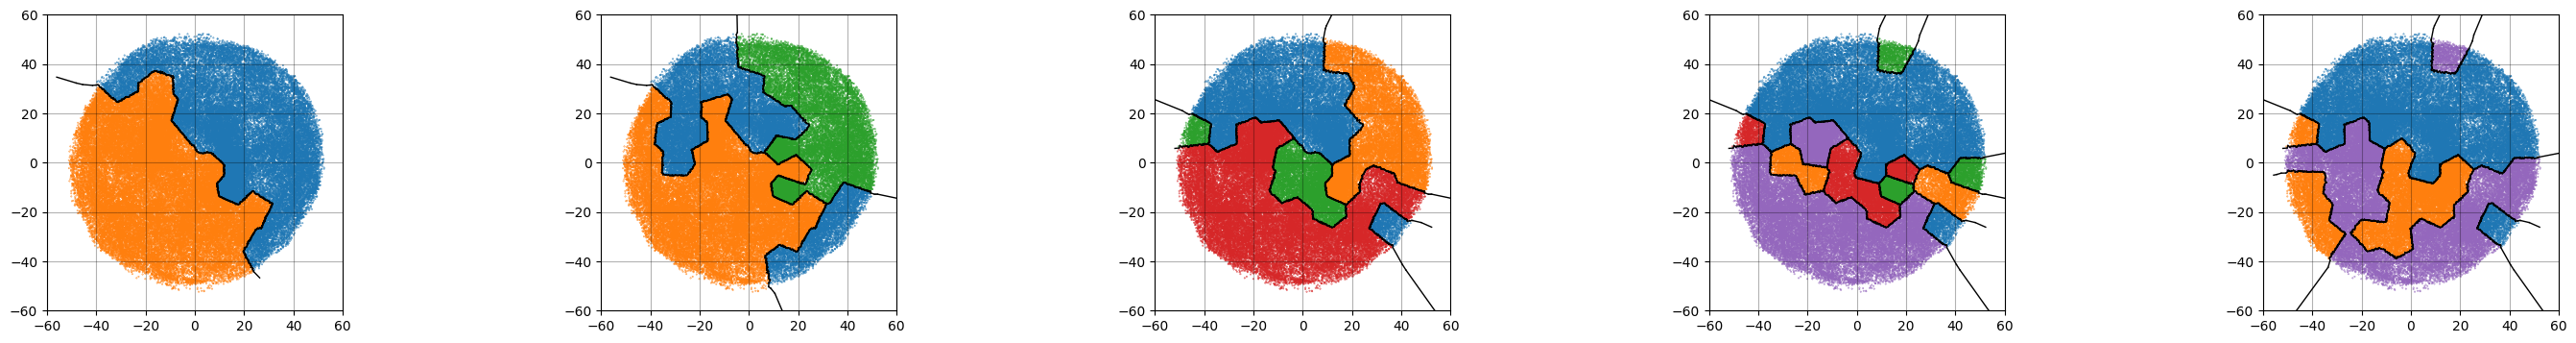

In [11]:
import os
from deeptime.markov.tools.analysis import mfpt


fig, ax = plt.subplots(1, 5)
fig.set_size_inches(36, 4)

for n_metastable_sets in range(2, 7):
    print(n_metastable_sets)
    pcca, metastabled_trajs_concat, boundary_lines = compute_metastable_states(msm_models[n_clusters][lagtime], n_metastable_sets, np.concatenate(trajs), np.concatenate(clustered_trajs[n_clusters]))
    pickle.dump(metastabled_trajs_concat, open(f"{pickle_dir}/metastabled_trajs_concat_{n_metastable_sets}.pickle", "wb"))
    pickle.dump(boundary_lines,           open(f"{pickle_dir}/boundary_lines_{n_metastable_sets}.pickle", "wb"))
    plot_metastable_states(ax[n_metastable_sets-2], np.concatenate(trajs), metastabled_trajs_concat)
    plot_voronoi_boundary(ax[n_metastable_sets-2], boundary_lines)

    print(pcca.coarse_grained_transition_matrix)
    print(pcca.coarse_grained_stationary_probability)
    print(mfpt(pcca.coarse_grained_transition_matrix, 0))
    print(mfpt(pcca.coarse_grained_transition_matrix, 1))
    print()

    ax[n_metastable_sets-2].set_xlim(-60, 60)
    ax[n_metastable_sets-2].set_ylim(-60, 60)
    ax[n_metastable_sets-2].set_xticks(range(-60, 61, 20))
    ax[n_metastable_sets-2].set_yticks(range(-60, 61, 20))

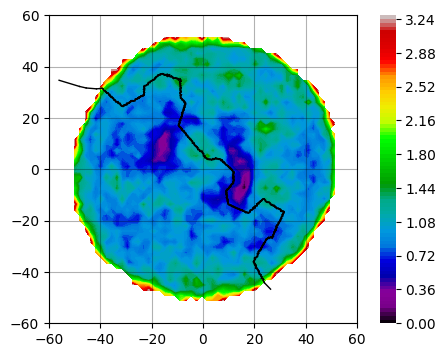

In [12]:
fig, ax = plt.subplots(1, 1)
fig.set_size_inches(6, 4)

plot_energy_landscape(ax, msm_models[n_clusters][lagtime], trajs, clustered_trajs[n_clusters])

_, _, boundary_lines = compute_metastable_states(msm_models[n_clusters][lagtime], 2, np.concatenate(trajs), np.concatenate(clustered_trajs[n_clusters]))
plot_voronoi_boundary(ax, boundary_lines)

ax.set_xlim(-60, 60)
ax.set_ylim(-60, 60)
ax.set_xticks(range(-60, 61, 20))
ax.set_yticks(range(-60, 61, 20))

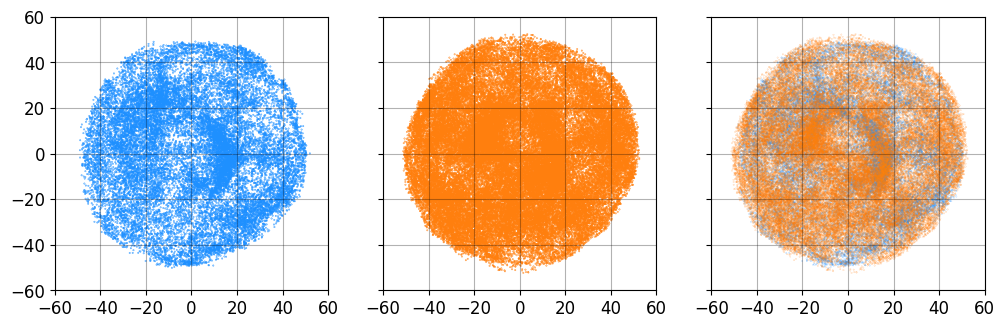

In [13]:
fig, ax = plt.subplots(1, 3)
fig.set_size_inches(12, 4)

metastabled_trajs_concat = pickle.load(open("./pickle-cache/pca_tetranucl/metastabled_trajs_concat_2.pickle", "rb"))

colors = ["#1E90FF", "tab:orange"]
trajs_concat = np.concatenate(trajs)
ax[0].scatter(trajs_concat[metastabled_trajs_concat==0, 0], trajs_concat[metastabled_trajs_concat==0, 1], c=[colors[int(state)%2] for state in metastabled_trajs_concat if state==0], s=0.1)
ax[1].scatter(trajs_concat[metastabled_trajs_concat==1, 0], trajs_concat[metastabled_trajs_concat==1, 1], c=[colors[int(state)%2] for state in metastabled_trajs_concat if state==1], s=0.1)
ax[2].scatter(trajs_concat[:, 0], trajs_concat[:, 1], c=[colors[int(state)%2] for state in metastabled_trajs_concat], s=0.01)

for i_ax in range(3):
    ax[i_ax].set_xlim(-60, 60)
    ax[i_ax].set_ylim(-60, 60)
    
    ax[i_ax].set_xticks(range(-60, 61, 20))
    ax[i_ax].set_yticks(range(-60, 61, 20))
    ax[i_ax].tick_params(axis="x", labelsize=12)
    ax[i_ax].tick_params(axis="y", labelsize=12)
    
    ax[i_ax].grid(True, color="black", alpha=0.3)
    ax[i_ax].set_aspect("equal", adjustable="box")

    if i_ax != 0:
        ax[i_ax].set_yticklabels([])